In [1]:

using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
include("run_sim.jl")
include("conv_spikes.jl") 
# include("firing_rates_max.jl") 


conv_spikes (generic function with 1 method)

In [2]:
@pyimport wandb
wandb.login(key="04a3943a16046e23c3b1a946c43cfb657e4b1f8d")


wandb: Currently logged in as: nmt121 (natmtc). Use `wandb login --relogin` to force relogin
wandb: Appending key for api.wandb.ai to your netrc file: /Users/nmt121/.netrc


true

### MN parameters 

#### All types of motoneurons merged

In [2]:
######################  ALL TYPES #######################
#########################################################
nr_s = 10

division_nr_s= trunc(Int, nr_s/3)+1#three types of motoneurons (S-type, FR-type and FF-type)


# Radius and soma lengths

rheobase_S = vcat(LinRange(3.5,6.5,division_nr_s), LinRange(6.5,17.5,division_nr_s), LinRange(17.5,25.10 ,nr_s - division_nr_s*2))
rs_S = vcat(LinRange(38.75,41.25,division_nr_s), LinRange(41.25,43.75,division_nr_s), LinRange(43.75,56.50 ,nr_s - division_nr_s*2))./10000
ls_S = vcat(LinRange(77.50,82.50,division_nr_s), LinRange(82.50,87.50,division_nr_s), LinRange(87.5,113.0 ,nr_s - division_nr_s*2))./10000
rms_S = vcat(LinRange(1.15,1.05,division_nr_s), LinRange(1.05,0.95,division_nr_s), LinRange(0.95,0.65 ,nr_s - division_nr_s*2)).*1000
rd_S = vcat(LinRange(20.75,31.25,division_nr_s), LinRange(31.25,41.75,division_nr_s), LinRange(41.75,46.25,nr_s - division_nr_s*2))./10000
ld_S = vcat(LinRange(5500.,6800.,division_nr_s), LinRange(6800.,8100.,division_nr_s), LinRange(8100,10600,nr_s - division_nr_s*2))./10000
rmd_S = vcat(LinRange(14.4,10.70,division_nr_s), LinRange(10.7,6.95,division_nr_s), LinRange(6.95,6.05,nr_s - division_nr_s*2)).*1000


#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S =  vcat(ones(division_nr_s)*4, LinRange(4.,2.25,division_nr_s), LinRange(2.25,0.5 ,nr_s - division_nr_s*2))
max_gks_S = vcat(LinRange(16.,25.,division_nr_s), LinRange(25.,19.,division_nr_s), LinRange(19.,4. ,nr_s - division_nr_s*2))
max_gca_S =  vcat(LinRange(0.038,0.029,division_nr_s), LinRange(0.029,0.016,division_nr_s), LinRange(0.016,0.012 ,nr_s - division_nr_s*2))

# Rate constants of the kinetic processes in ms^-1
αm = 22.0
βm = 13.0
αh_S = vcat(ones(division_nr_s)*0.5, LinRange(0.5,11.25,division_nr_s), LinRange(11.25,22.,nr_s - division_nr_s*2))
βh_S = vcat(ones(division_nr_s)*4., LinRange(4.,13.,division_nr_s), LinRange(13.,22.,nr_s - division_nr_s*2))
αn_S = vcat(ones(division_nr_s)*1.5, LinRange(1.5,11.75,division_nr_s), LinRange(11.75,22.,nr_s - division_nr_s*2))
βn_S = vcat(ones(division_nr_s)*0.1, LinRange(0.1,11.05,division_nr_s), LinRange(11.05,22.,nr_s - division_nr_s*2))
αq_S = vcat(ones(division_nr_s)*1.5, LinRange(1.5,11.75,division_nr_s), LinRange(11.75,22.,nr_s - division_nr_s*2))
βq_S = vcat(LinRange(0.025,0.038,division_nr_s), LinRange(0.038,11.025,division_nr_s), LinRange(11.025,22.,nr_s - division_nr_s*2))
αp = 0.008
βp= vcat(LinRange(0.014,0.016,division_nr_s), LinRange(0.016,0.019,division_nr_s), LinRange(0.019,0.020,nr_s - division_nr_s*2))
βp_S = vcat(LinRange(0.014,0.016,division_nr_s), LinRange(0.016,0.019,division_nr_s), LinRange(0.019,0.020,nr_s - division_nr_s*2))

Vthca_S = vcat(LinRange(2.5,3.,division_nr_s), LinRange(3.,8.,division_nr_s), LinRange(8,8.5,nr_s - division_nr_s*2)) # .+ rand(Normal(0.0,0.028),nr_s) # voltage threshold to Ca conductance
Apeak_S = vcat(LinRange(0.103,0.123,division_nr_s), LinRange(0.123,0.294,division_nr_s), LinRange(0.294,0.491,nr_s - division_nr_s*2)) #peak twitch amplitude in Newton (related to the strength of the response)
tpeak_S = vcat(LinRange(110.0,100.,division_nr_s), LinRange(73.5,55.5,division_nr_s), LinRange(82.3,56.9,nr_s - division_nr_s*2)) #time to peak in ms
tetanic_S = LinRange(0.393,0.491,nr_s);# tetanic force in Newton (max force that a muscle can produce when it's stimulated very rapidly)

#EXCITATORY PROFILE
amplitude=0.6
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

#AMPLIFICATION
γa=1.;

#INHIBITION FACTOR (SIZE ORDER)
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

# EF= LinRange(0.8,1.8, nr_s);

#HYSTERESIS

x_values = LinRange(-1, 1, nr_s)
A = 1.5  # amplitude of the exp
k= 10.0  # control rate ramp up and ramp down
γh = zeros(nr_s);
for i in 1:nr_s
    x = x_values[i]
    if x < 0
        γh[i] = A * exp(k * x)
    else 
        γh[i] = A * exp(-k * x)
    end

end
# γh= γh .+ 0.05;

γh = ones(nr_s);


EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 #reversal potentials
Ge=0.6; Gi=0.5 ; #maximun conductances
Vd0 = 0.; Vs0 = 0.;#initial voltages
rp=5.0; #refractory period
const step = 0.05;
_int(num) = floor(Int, num);
pd=0.6; #Pulse duration [mS]




#### Slow-type motoneurons

In [3]:
######################  S-TYPE ##########################
#########################################################
nr_s = 10

# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = 22.0; βm = 13.0
αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4
αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1
αq_S = ones(nr_s)*1.5
βq_S = ones(nr_s)*0.025
αp = 0.008
βp= LinRange(0.014,0.016,nr_s)
βp_S = ones(nr_s)*0.014

Vthca_S = LinRange(2.5,3.0,nr_s) 
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

#AMPLIFICATION
γa=1.;

#INHIBITION FACTOR (SIZE ORDER)
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion
# EF= LinRange(0.8,1.8, nr_s);

#HYSTERESIS
x_values = LinRange(-1, 1, nr_s)
A = 1.5  # amplitude of the exp
k= 10.0  # control rate ramp up and ramp down
γh = zeros(nr_s);
for i in 1:nr_s
    x = x_values[i]
    if x < 0
        γh[i] = A * exp(k * x)
    else
        γh[i] = A * exp(-k * x)
    end

end
# γh= γh .+ 0.05;

γh = zeros(nr_s);
# γh = [0.,0.,0.,0.12348,0.,0.,0.0902577,0.057332,0.,0.0491277]; #optimised values, test
# γh = [0.05006809989464373,0.05062841318517258,0.05579888020920921,0.10351099002087855,0.5433042529655824, 0.5444886490103167,0.13541465860474394,0.055798880209209215,0.061345798467742504,0.05006809989464373]
#reversal potentials
EL=0; 
ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 
#maximun conductances
Ge=0.6; Gi=0.5 ; 
#initial voltages
Vd0 = 0.; 
Vs0 = 0.;
#refractory period
rp=5.0; 
const step = 0.05;
_int(num) = floor(Int, num);
pd=0.6; #Pulse duration [mS]




In [11]:
######################  S-TYPE ##########################
#########################################################
nr_s = 10

# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = regressed_parameter[1,:]
ls_S = regressed_parameter[2,:] 
rms_S = regressed_parameter[3,:]
rd_S = regressed_parameter[4,:]
ld_S = regressed_parameter[5,:]
rmd_S = regressed_parameter[6,:]

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S = regressed_parameter[7,:]
max_gca_S = regressed_parameter[8,:]


# Rate constants of the kinetic processes in ms^-1
αm = 22.0; βm = 13.0
αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4
αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1
αq_S = ones(nr_s)*1.5
βq_S = ones(nr_s)*0.025
αp = 0.008
βp= regressed_parameter[9,:]
βp_S = ones(nr_s)*0.014

Vthca_S = regressed_parameter[10,:]
Apeak_S =  regressed_parameter[11,:]
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

#AMPLIFICATION
γa=1.;

#INHIBITION FACTOR (SIZE ORDER)
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion
# EF= LinRange(0.8,1.8, nr_s);

#HYSTERESIS
x_values = LinRange(-1, 1, nr_s)
A = 1.5  # amplitude of the exp
k= 10.0  # control rate ramp up and ramp down
γh = zeros(nr_s);
for i in 1:nr_s
    x = x_values[i]
    if x < 0
        γh[i] = A * exp(k * x)
    else
        γh[i] = A * exp(-k * x)
    end

end
# γh= γh .+ 0.05;

γh = zeros(nr_s);

#reversal potentials
EL=0; 
ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 
#maximun conductances
Ge=0.6; Gi=0.5 ; 
#initial voltages
Vd0 = 0.; 
Vs0 = 0.;
#refractory period
rp=5.0; 
const step = 0.05;
_int(num) = floor(Int, num);
pd=0.6; #Pulse duration [mS]




### MN parameters we need to fill with previous data (and creation of the dictionary)

In [12]:
ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp, :βp => βp_S[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm, :βm => βm, :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i],:αp => αp, :βp => βp[i],  :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;

### Running simulation

In [13]:
tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
commoninput = tr; #needed for the run_sim() function


In [14]:
full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0 #for creating the inhibitory signal
# tr=tr_new
@time spike_array, vs_array = run_sim();
# JLD2.@save "DR_070224.jld2" spike_array
# JLD2.@load "DR_070224.jld2" spike_array

 40.634933 seconds (1.81 G allocations: 30.021 GiB, 6.63% gc time, 0.49% compilation time)


([0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], [0.0 -0.002494824574604676 … -5.701280787252801 -5.701280787252801; 0.0 -0.0024858245027658435 … -5.585149238050355 -5.585149238050355; … ; 0.0 -0.002216431465425618 … -3.2951178274241855 -3.2951178274241855; 0.0 -0.0021890064815338196 … -3.13388123122507 -3.13388123122507])

In [30]:
# Plots.plot(vs_array[2,:])

##### Plotting with the excitatory input all together to compare

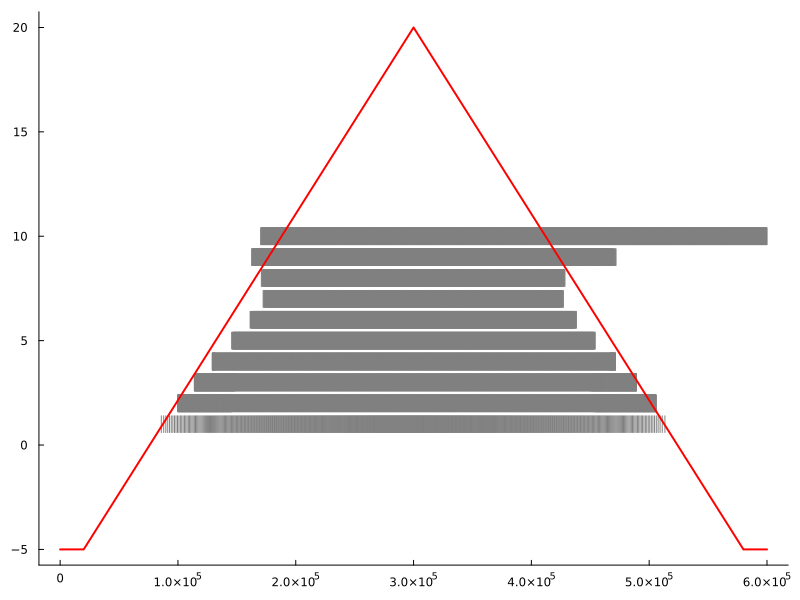

In [38]:
amplitude=0.4;
sim_length=560000 ;

half_triang = div(sim_length, 2);  # Half the total length minus plateau length, rounding down if necessary
flat_line = fill(-0.1, 20000);
up = range(-0.1, amplitude, length = half_triang + 1)  ;
down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line);


spike_times = []
neuron_ids = []
for i in 1:size(spike_array, 1)
    spikes = findall(spike_array[i, :] .== 1) #when the MNs fires 
    for t in spikes
        push!(spike_times, [t, t])
        push!(neuron_ids, [i - 0.4, i + 0.4])
    end
end

Plots.plot(spike_times, neuron_ids, line=(1), legend=false, color =:gray,size=(800, 600),grid = false)
Plots.plot!((tr/maximum(tr))*nr_s,line=(2), color =:red,grid = false)
# xlabel!()
# ylabel()


##### Faster way to plot for a Raster Visualitation

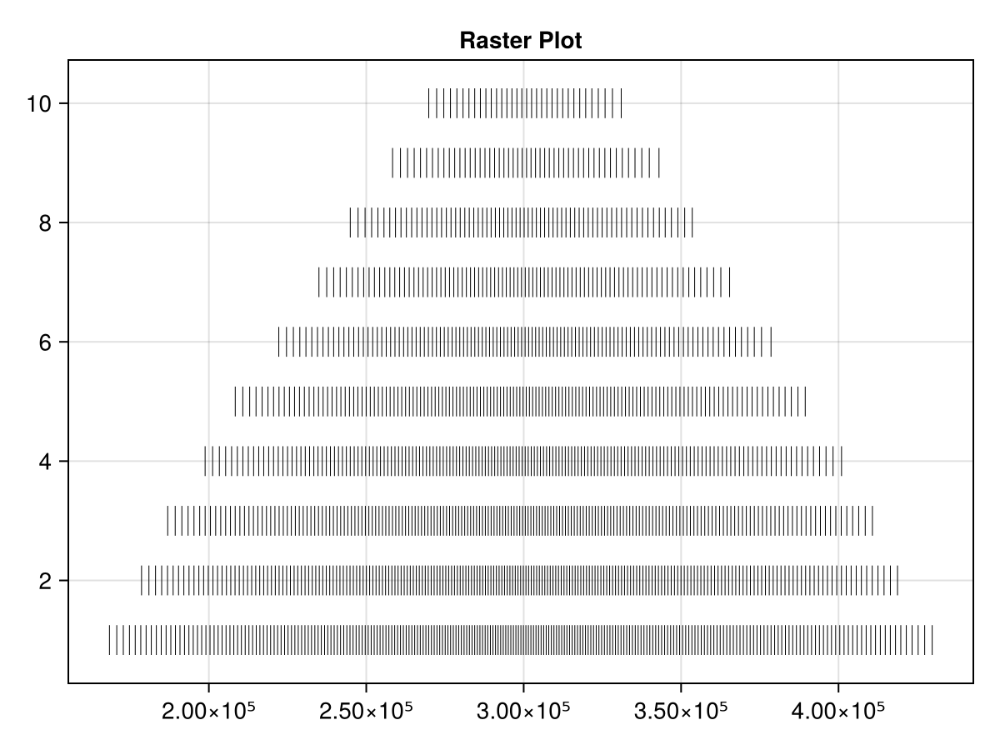

CairoMakie.Screen{IMAGE}


In [19]:
n_neurons, n_times = size(spike_array)
CairoMakie.activate!()

fig = Figure()

ax = Axis(fig[1, 1], title="Raster Plot")
line_height = 0.5
line_thickness = 0.5

# Define a small horizontal offset between spikes
horizontal_offset = 100  # Adjust this value as needed to separate the spikes

for t in 1:n_times
    for neuron in 1:n_neurons
        if spike_array[neuron, t] == 1.0
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * (neuron - 1)  # Adjust the multiplier for spacing
            lines!(ax, [(t + x_offset, neuron - line_height / 2), (t + x_offset, neuron + line_height / 2)], color=:black, linewidth=line_thickness)
        end
    end
end

# xlabel!(ax, "Time")
# ylabel!(ax, "Neuron")a
display(fig)


In [22]:
MN_list[7]

Dict{Any, Any} with 29 entries:
  :Cd      => 9.86512
  :VthCa   => 2.73524
  :Cs      => 0.200321
  :gc      => 0.964079
  :βn      => 0.1
  :βq      => 0.025
  :Apeak   => 0.11241
  :gNa     => 6.00962
  :Irh     => 5.60157
  :βh      => 4.0
  :Rn      => 1.63248
  :αp      => 0.008
  :αq      => 1.5
  :IF      => 1.0
  :Tetanic => 0.458333
  :gKf     => 0.801283
  :gKs     => 4.05336
  :gCa     => 0.333102
  :αh      => 0.5
  ⋮        => ⋮

## W&B - Hyperparameter sweep

In [15]:

function simulate_hh_hysteresis_constant_inh(γh::Vector,i,MN_list)    
    MN_list[i][:γh] = γh[1]

    MNs= MN_list[i]

    spike_array, _ = run_sim_optim_constant_inh(i);

    amplitude=0.4;
    sim_length=560000 ;
    half_triang = div(sim_length, 2);  
    flat_line = fill(-0.1, 20000);
    up = range(-0.1, amplitude, length = half_triang + 1)  ;
    down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
    tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
    equiv_force_profile= (tr/maximum(tr))*nr_s

    hysteresis= []

    if !isempty(spike_array) && any(spike_array[1, :] .== 1)
            
        value_1= equiv_force_profile[findfirst(==(1),spike_array[1,:]),:] #force at the recruitment threshold
        value_2=  equiv_force_profile[findlast(==(1),spike_array[1,:]),:] #force at the derecruitment threshold
        hysteresis= (value_2/value_1).-1

    else
        hysteresis=500 #random high value
    end

    max_firing_rates= [] #firing_rates_max(spike_array,i)
    
    return hysteresis, max_firing_rates
end


function run_sim_optim_constant_inh(i)

    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    # _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end




function firing_rates_max(spike_array,i)

    max_rates_mns=[]
    for i in 1: size(spike_array)[1]
        spike_pos=[]
        for j in 1:size(spike_array)[2]
            if spike_array[i,j]==1.0
                push!(spike_pos,j)
            end
        end
        ISI= diff(spike_pos);
        rates= 1 ./(ISI/20000)
        max_rates= maximum(rates)
        max_rates_mns=max_rates
        
    end
    
    max_rate_mn= max_rates_mns;
    
    return max_rate_mn;
    
    end




firing_rates_max (generic function with 1 method)

In [26]:
run_sim_optim_constant_inh(7)

([0 0 … 0 0], [0.0 -0.000593039506856415 … -1.998914956695463 -1.998914956695463; 0.0 -0.0024805088547189547 … -5.518682213559577 -5.518682213559577; … ; 0.0 -0.002208511268142018 … -3.247693735335718 -3.247693735335718; 0.0 -0.0021809236446641714 … -3.0879077618473807 -3.0879077618473807])

In [10]:
# i = 1

# lg = WandbLogger(project="BiophysicalModelOptimization_4April_New", name="Optimize1", config=Dict("gamma_h" => 0.0,"inh" => -1.0))

# γh_range = LinRange(0., 1., 10)
# factor_range = LinRange(-1., 1., 10)

# inh_input= []

# for j in 1:length(γh_range)  

#     for k in 1:length(γh_range)

#         MN_list[i][:γh] = γh_range[j]  

#         inh_input= fill(factor_range[k]*amplitude, sim_length)

#         hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)  
        
#         Wandb.log(lg, Dict("gamma_h" => γh_range[j],"inh" => inh_input[1], "hysteresis" => hysteresis))


#     end

# end

# # To finish and close the Wandb run
# Wandb.finish(lg)



wandb: wandb version 0.16.6 is available!  To upgrade, please run:
wandb:  $ pip install wandb --upgrade
wandb: Tracking run with wandb version 0.16.4
wandb: Run data is saved locally in /Users/nmt121/Desktop/Biophysical_model_mn/wandb/run-20240404_112248-2ok35eer
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Optimize1.1
wandb:  View project at https://wandb.ai/natmtc/BiophysicalModelOptimization_4April_
wandb:  View run at https://wandb.ai/natmtc/BiophysicalModelOptimization_4April_/runs/2ok35eer


UndefVarError: UndefVarError: hysteresis not defined

In [29]:
i=6

lg = WandbLogger(project="BiophysicalModelOptimization_4April_New", name="Optim6", config=Dict("gamma_h" => 0.0, "inh" => -1.0))

γh_range = LinRange(0., 1., 10)
factor_range = LinRange(-1., 1., 10)

inh_input = []
experiment_phase = 0 

for j in 1:length(γh_range)

    experiment_phase += 1

    for k in 1:length(factor_range)
        MN_list[i][:γh] = γh_range[j]

        inh_input = fill(factor_range[k] * amplitude, sim_length)

        hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)

        Wandb.log(lg, Dict("gamma_h" => γh_range[j], "inh" => inh_input[1], "hysteresis" => hysteresis, "experiment_phase" => experiment_phase))
    end
end

Wandb.finish(lg)


wandb: wandb version 0.16.6 is available!  To upgrade, please run:
wandb:  $ pip install wandb --upgrade
wandb: Tracking run with wandb version 0.16.4
wandb: Run data is saved locally in /Users/nmt121/Desktop/Biophysical_model_mn/wandb/run-20240404_161552-8afp0gmq
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Optim6
wandb:  View project at https://wandb.ai/natmtc/BiophysicalModelOptimization_4April_New
wandb:  View run at https://wandb.ai/natmtc/BiophysicalModelOptimization_4April_New/runs/8afp0gmq
wandb: WARNING No program path found, not creating job artifact. See https://docs.wandb.ai/guides/launch/create-job
wandb:                                                                                
wandb: 
wandb: Run summary:
wandb: experiment_phase 10
wandb:          gamma_h 1.0
wandb:       hysteresis -0.14344
wandb:              inh 0.4
wandb: 
wandb:  View run Optim6 at: https://wandb.ai/natmtc/BiophysicalModelOptimization_4April_New/runs/8afp0gmq
wandb: Synced 

In [35]:
Wandb.close(lg)


In [28]:
i = 7

# Initialize the WandbLogger with the project and run name
lg = WandbLogger(project="BiophysicalModelOptimization_4April_New", name="trial7", config=Dict("gamma_h" => 0.0, "inh" => -1.0))

γh_range = LinRange(0., 1., 10)
factor_range = LinRange(-1., 1., 10)

inh_input = []

# Initialize a step counter
step_counter = 0

for j in 1:length(γh_range)
    for k in 1:length(factor_range)
        MN_list[i][:γh] = γh_range[j]
        inh_input = fill(factor_range[k] * amplitude, sim_length)

        hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)

        # Log the data with the step_counter as the step value
        Wandb.log(lg, Dict("gamma_h" => γh_range[j], "inh" => inh_input[1], "hysteresis" => hysteresis, "experiment_phase" => j, "_step" => step_counter))

        # Increment the step counter after each log
        step_counter += 1
    end
end

# Finish the run
Wandb.close(lg)


wandb: wandb version 0.16.6 is available!  To upgrade, please run:
wandb:  $ pip install wandb --upgrade
wandb: Tracking run with wandb version 0.16.4
wandb: Run data is saved locally in /Users/nmt121/Desktop/Biophysical_model_mn/wandb/run-20240404_160801-0fy3pmsx
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run trial7
wandb:  View project at https://wandb.ai/natmtc/BiophysicalModelOptimization_4April_New
wandb:  View run at https://wandb.ai/natmtc/BiophysicalModelOptimization_4April_New/runs/0fy3pmsx
wandb: WARNING No program path found, not creating job artifact. See https://docs.wandb.ai/guides/launch/create-job
wandb:                                                                                
wandb: 
wandb: Run summary:
wandb: experiment_phase 10
wandb:          gamma_h 1.0
wandb:       hysteresis -0.14167
wandb:              inh 0.4
wandb: 
wandb:  View run trial7 at: https://wandb.ai/natmtc/BiophysicalModelOptimization_4April_New/runs/0fy3pmsx
wandb: Synced 

In [23]:

i = 1

γh_range = LinRange(0., 1., 10)[6:10]
factor_range = LinRange(-1., 1., 10)[6:10]

inh_input = []

for j in 1:length(γh_range)
    
    for k in 1:length(factor_range)

        run_name = "gamma_h_" * string(γh_range[j]) * "_inh_" * string(amplitude*factor_range[k])
        lg = WandbLogger(project="MN1", name=run_name, config=Dict("gamma_h" => γh_range[j], "inh" => factor_range[k]*amplitude))


        MN_list[i][:γh] = γh_range[j]


        inh_input = fill(factor_range[k] * amplitude, sim_length)

        hysteresis, _ = simulate_hh_hysteresis_constant_inh([γh_range[j]], i, MN_list)

        Wandb.log(lg, Dict("gamma_h" => γh_range[j], "inh" => inh_input[1], "hysteresis" => hysteresis))

        Wandb.close(lg)
    end
end



wandb: wandb version 0.16.6 is available!  To upgrade, please run:
wandb:  $ pip install wandb --upgrade
wandb: Tracking run with wandb version 0.16.4
wandb: Run data is saved locally in /Users/nmt121/Desktop/Biophysical_model_mn/wandb/run-20240404_174755-omiqr1kt
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run gamma_h_0.5555555555555556_inh_0.04444444444444447
wandb:  View project at https://wandb.ai/natmtc/MN1
wandb:  View run at https://wandb.ai/natmtc/MN1/runs/omiqr1kt
wandb: WARNING No program path found, not creating job artifact. See https://docs.wandb.ai/guides/launch/create-job
wandb:                                                                                
wandb: 
wandb: Run summary:
wandb:    gamma_h 0.55556
wandb: hysteresis -0.21787
wandb:        inh 0.04444
wandb: 
wandb:  View run gamma_h_0.5555555555555556_inh_0.04444444444444447 at: https://wandb.ai/natmtc/MN1/runs/omiqr1kt
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 

In [21]:
γh_range = LinRange(0., 1., 10)[6:10]
# γh_range[6:10]

5-element LinRange{Float64}:
 0.555556,0.666667,0.777778,0.888889,1.0

In [ ]:
run(`wandb sync`)


## Analysis of the distribution

In [7]:
amplitude=0.4;
sim_length=560000 ;
half_triang = div(sim_length, 2);  
flat_line = fill(-0.1, 20000);
up = range(-0.1, amplitude, length = half_triang + 1)  ;
down = range(amplitude, -0.1, length = sim_length - half_triang + 1);  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line);
equiv_force_profile= (tr/maximum(tr))*nr_s

recr_inter_input= zeros(1,nr_s)
derecr_inter_input= zeros(1,nr_s)
hysteresis=zeros(1,nr_s)

for n in 1:nr_s
    recr_inter_input[1,n]= equiv_force_profile[findfirst(==(1),spike_array[n,:]),:][1] #force at the recruitment threshold relative to the defined exc input
    derecr_inter_input[1,n]=  equiv_force_profile[findlast(==(1),spike_array[n,:]),:][1] #force at the derecruitment threshold

    hysteresis[1,n]= (derecr_inter_input[1,n]/recr_inter_input[1,n]).-1

end

# print(((value_2/value_1).-1)[1])

In [8]:
data_exp = DataFrame(CSV.File("/Users/nmt121/Desktop/Data_MN_Model/S5_short_hyst.csv"))
hysteresis_exp= (data_exp[:,2]./ data_exp[:,1]).-1; #(force(derecruitment)/force(recruitment))-1
recruitment_experimental_normal= data_exp[:,1];
derecruitment_experimental_normal= data_exp[:,2];


In [9]:
function normalize_to_range(vector, new_min, new_max)
    min_val = minimum(vector)
    max_val = maximum(vector)
    return ((vector .- min_val) / (max_val - min_val)) * (new_max - new_min) .+ new_min
end

simulated_values = vcat(recr_inter_input[1, :], derecr_inter_input[1, :])
normalized_recr = normalize_to_range(simulated_values, 0, 100)

println("Normalized Recr: ", normalized_recr)


recr_sim=  normalized_recr[1:10]; derecr_sim=  normalized_recr[11:10];



Normalized Recr: [0.0, 8.575707797854877, 18.61242632138371, 28.63368441395306, 40.16136824813994, 52.01372113247656, 66.7581408831771, 73.70277321480336, 88.30321770219348, 97.59107160112089, 2.2775147357232552, 9.459851193352021, 20.462846651850427, 31.51222340322738, 42.008889747801724, 53.47763068895542, 67.81718040390376, 73.95110638709055, 91.40303410957583, 100.0]


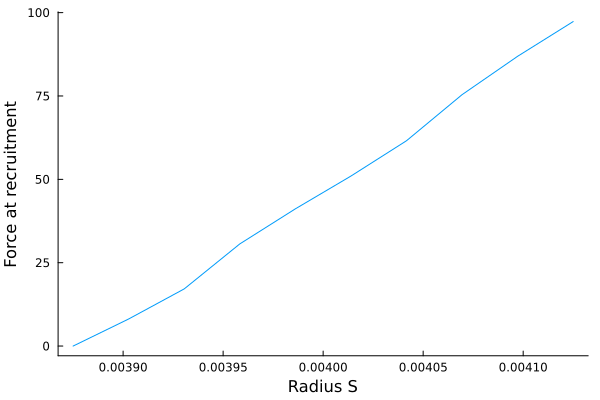

In [12]:
p = Plots.plot(layout = (1, 1))

Plots.plot!(p[1], rs_S, recr_sim, grid=false,legend=false, xlabel="Radius S",ylabel="Force at recruitment")
# Plots.plot!(p[2], ls_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Length S",ylabel="Force at recruitment")
# Plots.plot!(p[3], rd_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Radius D",ylabel="Force at recruitment")
# Plots.plot!(p[4], ld_S, recr_inter_input[1,:], grid=false,legend=false,xlabel="Length D",ylabel="Force at recruitment")


display(p)

In [10]:
regressed_parameter = zeros(11, nr_s)
vars= ["rs_S","ls_S","rms_S","rd_S","ld_S","rmd_S", "max_gks_S","max_gca_S","βp","Vthca_S","Apeak_S"]

for i in 1:11 #for each of the variables we are interested in
    for j in 1:nr_s
        var_interest= vars[i]
        var_interest= eval(Meta.parse(var_interest))
        X = hcat(ones(length(var_interest)), var_interest)
        model = lm(X, recr_sim) 
        b = coef(model) 
        regressed_parameter[i,j] = (recruitment_experimental_normal[j]-b[1])/ b[2]
    end
end
regressed_parameter


11×10 Matrix{Float64}:
     0.00388823      0.0038944   …      0.00405735      0.00407313
     0.00777646      0.0077888          0.0081147       0.00814626
  1144.71         1142.24            1077.06         1070.75
     0.00213056      0.00215648         0.00284088      0.00290714
     0.556879        0.560088           0.644823        0.653026
 14204.2         14112.9         …  11701.2         11467.7
    16.4762         16.6984            22.5647         23.1326
     0.0375238       0.0373016          0.0314353       0.0308674
     0.0141058       0.0141552          0.0154588       0.015585
     2.52646         2.5388             2.8647          2.89626
     0.104058        0.104552    …      0.117588        0.11885

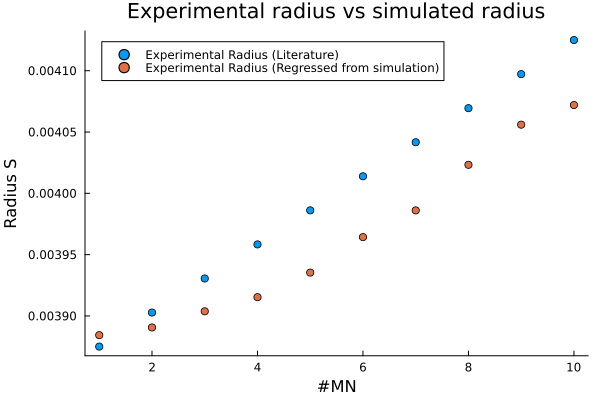

In [13]:
p = Plots.scatter([1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Radius S", title="Experimental radius vs simulated radius",label= "Experimental Radius (Literature)")
Plots.scatter!([1,2,3,4,5,6,7,8,9,10], regressed_parameter[:], grid=false, label= "Experimental Radius (Regressed from simulation)")

display(p)


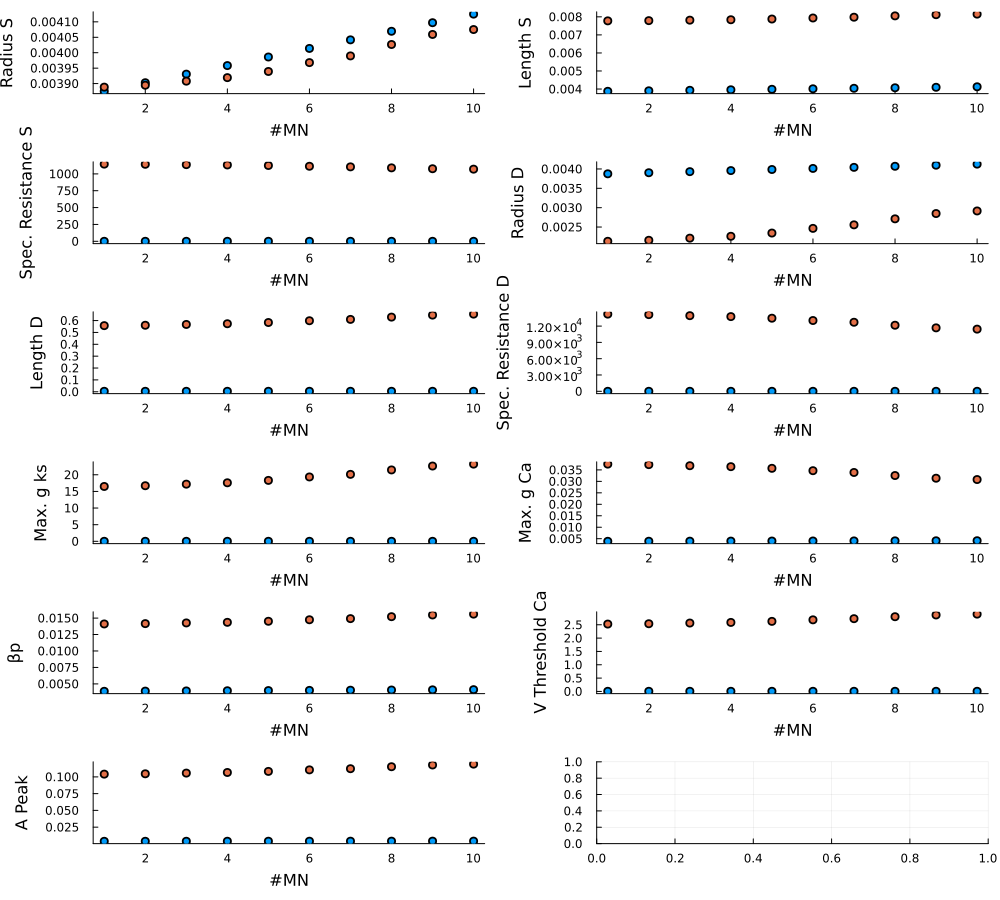

In [14]:
default(size=(1000, 900))

p = Plots.plot(layout = (6, 2))

Plots.scatter!(p[1,1], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Radius S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[1,1], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[1,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[1,2], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Length S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[1,2], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[2,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[2,1], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Spec. Resistance S", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[2,1], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[3,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[2,2], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Radius D",legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[2,2], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[4,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[3,1], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Length D", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[3,1], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[5,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[3,2], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Spec. Resistance D",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[3,2], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[6,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[4,1], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Max. g ks", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[4,1], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[7,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[4,2], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="Max. g Ca",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[4,2], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[8,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[5,1], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="βp", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[5,1], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[9,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[5,2], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="V Threshold Ca",  legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[5,2], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[10,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

Plots.scatter!(p[6,1], [1,2,3,4,5,6,7,8,9,10], rs_S, grid=false, xlabel="#MN", ylabel="A Peak", legend=false)#label="Experimental Radius (Literature)")
Plots.scatter!(p[6,1], [1,2,3,4,5,6,7,8,9,10], regressed_parameter[11,:], grid=false, legend=false)#label="Experimental Radius (Regressed from simulation)")

# Finally, display the complete layout
display(p)


## Computation of the rates 

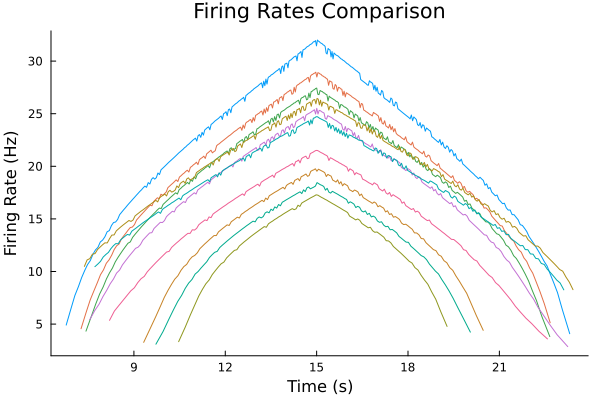

In [10]:
sampling_rate = 20000 # Hz

all_timebases = []
all_rates = []

for mn in 1:size(spike_array, 1)
    spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
    timebase, rates = calculate_rates_with_timebase(spike_pos, sampling_rate)
    push!(all_timebases, timebase)
    push!(all_rates, rates)
end

p = Plots.plot(legend=false, grid=false, xlabel="Time (s)", ylabel="Firing Rate (Hz)", title="Firing Rates Comparison")
for i in 1:length(all_rates)
    if !isempty(all_rates[i])
        Plots.plot!(p, all_timebases[i], all_rates[i], legend=false, grid=false)
    end
end

display(p)

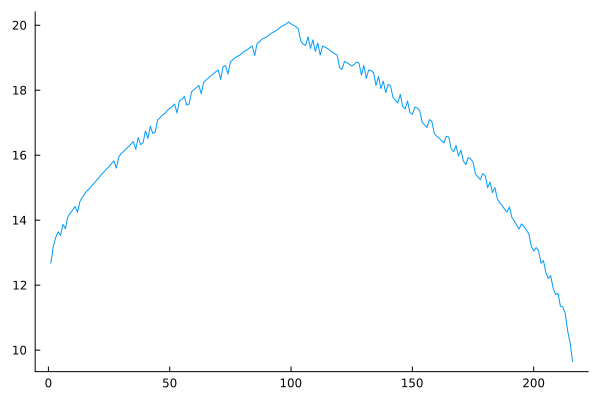

In [70]:
n=5
spike_pos1= []
for i in 1:length(spike_array[n,:])
    if spike_array[n,i]==1.0
        push!(spike_pos1,i)
    end
end
ISI= diff(spike_pos1);
rates_1= 1 ./(ISI/20000);

Plots.plot(rates_1,legend=false,grid=false)

In [ ]:
rates = zeros(10, 200) # Initialize rates matrix

for i in 1:10
    spike_pos1 = []
    for j in 1:size(spike_array, 2) 
        if spike_array[i,j] == 1.0
            push!(spike_pos1, j)
        end
    end
    if !isempty(spike_pos1)
        ISI = diff(spike_pos1) 
        rate = 1 ./ (ISI / 20000) #
    end
end

# Plot the average firing rate for the first neuron
Plots.plot(rates[1,:], legend=false, grid=false)

In [ ]:
rates= zeros(20,1000)
ISIs= zeros(1,20)
for i in 1:20
spike_pos= []
    for j in 1:length(spike_array[i,:])
        if spike_array[i,j]==1.0
            push!(spike_pos,j)
        end
    end
    ISI= diff(spike_pos);
    ISIs[i]= length(ISI)
    c=(1 ./(ISI/20000))
    rates[i,1:end]=vcat(c, zeros(1000-length(c)));

end

current = zeros(20,maximum(Int.(ISIs)))
cool_colors_manual = range(colorant"blue", stop=colorant"red", length=20)

tr=(tr/maximum(tr))*20
for i in 1:size(spike_array, 1)
    spikes = (findall(spike_array[i, :] .== 1)) #when the MNs fires 
    for j in 1:(size(spikes, 1)-1)
        val= spikes[j]
        val_next= spikes[j+1]
        current[i,j]= mean(tr[val:val_next])

    end

end

p=plot()
for i in 10
    rate_correct= filter(x -> x != 0, rates[i,:])
    current_correct= filter(x -> x != 0, current[i,:])
    plot!(current_correct, rate_correct,legend=false,linecolor=cool_colors_manual[i],grid = false)#,ISI,legend=false)
    scatter!([current_correct[1]], [rate_correct[1]], markercolor=cool_colors_manual[i], marker=:circle, markersize=5,grid = false)
    scatter!([current_correct[end]], [rate_correct[end]], markercolor=cool_colors_manual[i], marker=:cross, markersize=5,grid = false)
    # println(current_correct[1], current_correct[end])

end


# display(p)

##### other way of plotting considering first and last spike separately

In [ ]:
rates= zeros(20,1002)
ISIs= zeros(1,20)
for i in 1:20
spike_pos= []
    for j in 1:length(spike_array[i,:])
        if spike_array[i,j]==1.0
            push!(spike_pos,j)
        end
    end
    ISI= diff(spike_pos);
    ISIs[i]= length(ISI)
    c=(1 ./(ISI/20000))
    # rates[i,1:end]=vcat(c, zeros(1000-length(c)));
    rates[i,2:end-1]=vcat(c, zeros(1000-length(c)));
    rates[i,1]=rates[i,2]-0.1; 
    rates[i,end]=c[end]-0.1;
end



# current = zeros(20,maximum(Int.(ISIs)))
current = zeros(20,maximum(Int.(ISIs).+2))


cool_colors_manual = range(colorant"blue", stop=colorant"red", length=20)

tr=(tr/maximum(tr))*20
for i in 1:size(spike_array, 1)
    spikes = (findall(spike_array[i, :] .== 1)) #when the MNs fires 

    val_start=spikes[1];val_end=spikes[end]
    current[i,1]= tr[val_start]
    current[i,end]= tr[val_end]
    for j in 1:(size(spikes, 1)-1)
        val= spikes[j]
        val_next= spikes[j+1]
        current[i,j+1]= mean(tr[val:val_next])
        # current[i,j]= mean(tr[val:val_next])

    end




end

p=plot()
for i in 1:20
    rate_correct= filter(x -> x != 0, rates[i,:])
    current_correct= filter(x -> x != 0, current[i,:])
    plot!(current_correct, rate_correct,legend=false,linecolor=cool_colors_manual[i])#,ISI,legend=false)ç
    scatter!([current_correct[1]], [rate_correct[1]], markercolor=cool_colors_manual[i], marker=:circle, markersize=5)
    scatter!([current_correct[end]], [rate_correct[end]], markercolor=cool_colors_manual[i], marker=:cross, markersize=5)
    # println(current_correct[1], current_correct[end])

end



display(p)






## CONTROLLER

In [ ]:
smoothed_spike_array1,smoothed_spike_array2= conv_spikes(spike_array, 10,11)

In [ ]:
# # # color = range(1, stop=length(spike_array[1,:]), length=length(spike_array[1,:]))
# p = plot(smoothed_spike_array1, smoothed_spike_array2,legend=false, grid=false)#, line_z=color, linewidth=2, color=:viridis,legend=false)#, colorbar= true,colorbar_title="Start-End", colorbar_ticks=[(1, " "), (length(spike_array[1,:]), "End")], legend=false)
# xticks!(p, [1], [" "])
# yticks!(p, [1], [" "])
# xlabel!(p, "DR 1")
# ylabel!(p, "DR 2")
# display(p)

In [ ]:
# p=plot(smoothed_spike_array1, smoothed_spike_array2,legend=false)
# x=0:0.0001:maximum(smoothed_spike_array1) ; y=x;

# p=plot!(x, y, line = (:red), ylim=(0, maximum(smoothed_spike_array1)),legend=false)

# # xticks!(p, [1], [" "])
# yticks!(p, [1], [" "])


In [ ]:
#DISCHARGE RATES AND IDEAL TRAJECTORIES FOR THE CONTROLLER:

dr_1_2= [smoothed_spike_array1 smoothed_spike_array2];

x = range(0, stop=maximum(smoothed_spike_array1), length=length(smoothed_spike_array1)+2)
y_values = LinRange(0., maximum(smoothed_spike_array1), length(smoothed_spike_array1)+2);
x_values = zeros(length(y_values));
vertical_line = hcat(x_values, y_values);

# x_values = LinRange(0., maximum(smoothed_spike_array1), length(smoothed_spike_array1) + 2);
# y_values = LinRange(0., maximum(smoothed_spike_array1), length(smoothed_spike_array1) + 2);
# diagonal_line = hcat(x_values, y_values);

#when doing it in 1D
# n = length(smoothed_spike_array1)  # Number of points
# x = LinRange(0, 2 * π, n)  # Generating n points between 0 and 2π
# ideal = sin.(x);


In [ ]:
tr_new= tr;
# tr_new

In [ ]:
kp = 0.9
kd = 0.2
dt = 0.1

trajectory2_controlled = copy(dr_1_2)
trajectory1 = diagonal_line
tr_new= tr

previous_error_vec = zeros(2)

for i in 1:(size(trajectory1, 1) - 2)

    error_vec = trajectory1[i, :] - trajectory2_controlled[i, :]
    euclidean_distance = sqrt(sum(error_vec .^ 2))
    
    if euclidean_distance != 0
        unit_vector = error_vec ./ euclidean_distance #Normalise the error vector to obtain a unit vector pointing in the direction of the error
    else
        unit_vector = zeros(2)
    end

    angle_theta = atan(unit_vector[2], unit_vector[1])

    if angle_theta < 0
        tr_new[i] -= 0.1
    elseif angle_theta > 0
        tr_new[i] += 0.1
    else
        # tr_new[j] remains the same
    end



    directed_error_vec = euclidean_distance .* unit_vector #Scale the unit vector by the Euclidean distance to get a directed error vector

    derivative_vec = (directed_error_vec - previous_error_vec) ./ dt
    output_vec = kp .* directed_error_vec + kd .* derivative_vec

    trajectory2_controlled[i, :] = trajectory2_controlled[i, :] + output_vec
    previous_error_vec = directed_error_vec
end


In [ ]:
# plot(trajectory2_controlled[:,1],trajectory2_controlled[:,2],linewidth=8,grid=false,legend=false)
# plot!(trajectory1[:,1],trajectory1[:,2],linewidth=5,grid=false,legend=false)